In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from credit_risk import config as C, data as D, features as F, scorecard as S, models as M
from credit_risk import calibration as CAL, business as B, fairness as FAIR, stability as ST
R = lambda s: json.load(open(C.REPORTS / f"metrics_{s}.json"))
def app():
    t = pd.read_parquet(C.ROOT / "data/synthetic/application_train.parquet")  # use data/raw + D.read_table for real data
    return F.engineer_application(D.clean_application(t)), t


# 02 - Feature engineering
Every engineered feature, how it is built and why (see `docs/feature_dictionary.md`).

In [2]:
df, _ = app()
pd.DataFrame(F.FEATURE_DICTIONARY, index=['how','why']).T.head(20)

,how,why
CREDIT_INCOME_RATIO,AMT_CREDIT / AMT_INCOME_TOTAL,Larger loans relative to income are harder to ...
ANNUITY_INCOME_RATIO,AMT_ANNUITY / AMT_INCOME_TOTAL,Payment burden: share of income consumed each ...
CREDIT_GOODS_RATIO,AMT_CREDIT / AMT_GOODS_PRICE,Above 1 means the borrower finances more than ...
ANNUITY_CREDIT_RATIO,AMT_ANNUITY / AMT_CREDIT,Proxy for loan term: high ratio = short term =...
INCOME_PER_FAMILY_MEMBER,AMT_INCOME_TOTAL / CNT_FAM_MEMBERS,Disposable income is shared across the household.
YEARS_EMPLOYED,-DAYS_EMPLOYED / 365.25 (sentinel -> NaN),Job stability.
EMPLOYED_TO_AGE_RATIO,YEARS_EMPLOYED / AGE_YEARS,Share of adult life in work. Age-derived: excl...
YEARS_REGISTRATION,-DAYS_REGISTRATION / 365.25,Residential/registration stability.
YEARS_ID_PUBLISH,-DAYS_ID_PUBLISH / 365.25,Recently re-issued ID can signal instability.
YEARS_PHONE_CHANGE,-DAYS_LAST_PHONE_CHANGE / 365.25,Recent phone change is a mild instability signal.


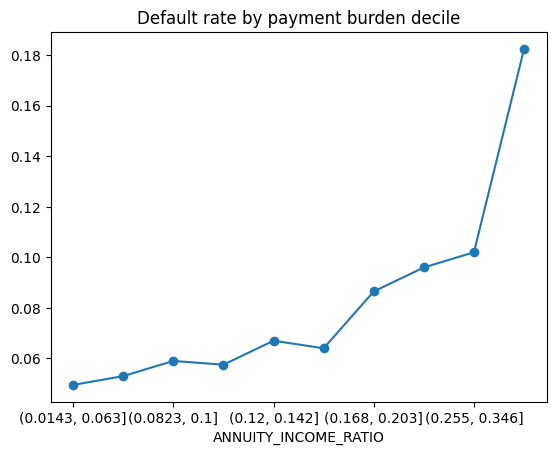

In [3]:
df.groupby(pd.qcut(df['ANNUITY_INCOME_RATIO'], 10))[C.TARGET].mean().plot(marker='o'); plt.title('Default rate by payment burden decile'); plt.show()

Stage B adds aggregates of bureau / previous applications / instalments / POS / cards, using only records dated before the application (`features.before_application`).